# Fairness and Bias Analysis in AI-Based Legal Decision Support
### A Practical Guide using Fairlearn, Scikit-Learn, and the COMPAS Dataset

---

## Overview & Legal Context
In criminal justice and civil legal decision support systems (such as pre-trial bail, sentencing recommendations, and recidivism risk assessment), algorithmic bias has profound real-world consequences:

1. **False Positive Rate (FPR) Disparity (Unjust Detention)**:
   * Individuals falsely predicted to re-offend or fail to appear in court face denied bail, longer pre-trial detention, and harsher sentences.
2. **False Negative Rate (FNR) Disparity (Overlooked Risk)**:
   * Individuals misclassified as low-risk may lead to unequal public safety risks.
3. **Selection Rate Disparity**:
   * Systematic inequality in who receives favorable vs. unfavorable legal recommendations.

In this notebook, we walk through:
* **Step 1**: Downloading and preparing real-world legal decision data (the ProPublica COMPAS dataset).
* **Step 2**: Auditing the commercial COMPAS AI risk scores using Fairlearn's `MetricFrame`.
* **Step 3**: Training an in-house baseline ML model and auditing its racial disparity.
* **Step 4**: Mitigating bias using Fairlearn's `ExponentiatedGradient` with `EqualizedOdds`.
* **Step 5**: Comparing results across all three approaches (Commercial AI vs. Baseline vs. Mitigated).


### Step 0: Imports and Environment Setup


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score

# Fairlearn modules
import fairlearn
from fairlearn.metrics import (
    MetricFrame,
    selection_rate,
    false_positive_rate,
    false_negative_rate,
    true_positive_rate,
    count
)
from fairlearn.reductions import ExponentiatedGradient, EqualizedOdds

# Plot styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
print(f"Fairlearn version: {fairlearn.__version__}")


Fairlearn version: 0.16.0.dev0


---
## Step 1: Load and Preprocess the Legal Dataset (COMPAS)

We will fetch the canonical ProPublica COMPAS Recidivism dataset. 
Each row represents a criminal defendant screened in Broward County, Florida.
Key fields:
- `two_year_recid`: **Actual outcome** (1 = arrested again within 2 years, 0 = not).
- `score_text`: **Commercial AI recommendation** (Low, Medium, High risk).
- `race`: **Protected demographic attribute**.
- `priors_count`, `c_charge_degree`, `age`: **Case features**.


In [13]:
# Load the raw ProPublica dataset
url = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"
df_raw = pd.read_csv(url)

# Apply standard ProPublica data cleaning methodology
df = df_raw[
    (df_raw['days_b_screening_arrest'] <= 30) &
    (df_raw['days_b_screening_arrest'] >= -30) &
    (df_raw['is_recid'] != -1) &
    (df_raw['c_charge_degree'] != 'O') &
    (df_raw['score_text'] != 'N/A')

].copy()


# Focus on African-American and Caucasian groups for direct disparity analysis
df = df[df['race'].isin(['African-American', 'Caucasian'])].copy()

print(f"Dataset shape after cleaning: {df.shape}")
df[['name', 'race', 'age', 'priors_count', 'c_charge_degree', 'score_text', 'two_year_recid']].head()


Dataset shape after cleaning: (5278, 53)


,name,race,age,priors_count,c_charge_degree,score_text,two_year_recid
1,kevon dixon,African-American,34,0,F,Low,1
2,ed philo,African-American,24,4,F,Low,1
6,edward riddle,Caucasian,41,14,F,Medium,1
8,elizabeth thieme,Caucasian,39,0,M,Low,0
10,benjamin franc,Caucasian,27,0,F,Low,0


---
## Step 2: Audit the Commercial AI Recommendation (COMPAS)

Here we evaluate the decisions made by the real-world COMPAS algorithm against the actual ground-truth recidivism outcome:
* **`y_true`**: `two_year_recid` (Actual outcome)
* **`y_pred`**: High/Medium risk score classified as positive (1), Low risk as negative (0)
* **`sensitive_features`**: `race`


In [18]:
# Extract the variables
y_actual = df['two_year_recid']
y_compas_ai = df['score_text'].apply(lambda x: 1 if x in ['Medium', 'High'] else 0)
sensitive_attr = df['race']

# Define critical legal metrics
legal_metrics = {
    "Sample Count": count,
    "Overall Accuracy": accuracy_score,
    "Selection Rate (High Risk %)": selection_rate,
    "False Positive Rate (Unjust Detention Risk)": false_positive_rate,
    "False Negative Rate (Overlooked Risk)": false_negative_rate,
    "Positive Predictive Value (Precision)": precision_score,
}

# Run the Fairlearn MetricFrame audit
compas_audit = MetricFrame(
    metrics=legal_metrics,
    y_true=y_actual,
    y_pred=y_compas_ai,
    sensitive_features=sensitive_attr
)

print("=== COMPAS COMMERCIAL AI AUDIT RESULTS ===")
display(compas_audit.by_group.round(3))

print("\n=== ABSOLUTE DISPARITIES (Difference across groups) ===")
display(compas_audit.difference().round(3))


=== COMPAS COMMERCIAL AI AUDIT RESULTS ===


,Sample Count,Overall Accuracy,Selection Rate (High Risk %),False Positive Rate (Unjust Detention Risk),False Negative Rate (Overlooked Risk),Positive Predictive Value (Precision)
race,,,,,,
African-American,3175.0,0.649,0.576,0.423,0.285,0.650
Caucasian,2103.0,0.672,0.331,0.220,0.496,0.595



=== ABSOLUTE DISPARITIES (Difference across groups) ===


Sample Count                                   1072.000
Overall Accuracy                                  0.023
Selection Rate (High Risk %)                      0.245
False Positive Rate (Unjust Detention Risk)       0.203
False Negative Rate (Overlooked Risk)             0.212
Positive Predictive Value (Precision)             0.055
dtype: float64

### Visualizing the Disparity in the Commercial AI Model
Notice the stark differences:
* Black defendants faced a **False Positive Rate of ~42%** vs. **~22%** for White defendants.
* White defendants faced a **False Negative Rate of ~50%** vs. **~28%** for Black defendants.


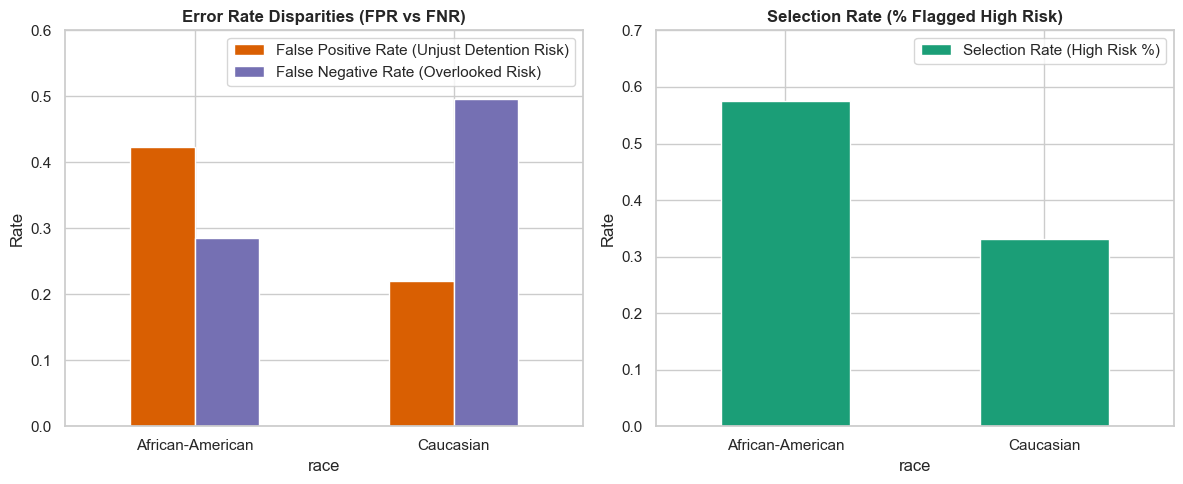

In [17]:
# Plot key disparities
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

compas_audit.by_group[["False Positive Rate (Unjust Detention Risk)", "False Negative Rate (Overlooked Risk)"]].plot(
    kind="bar", ax=axes[0], color=["#d95f02", "#7570b3"], rot=0
)
axes[0].set_title("Error Rate Disparities (FPR vs FNR)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Rate")
axes[0].set_ylim(0, 0.6)

compas_audit.by_group[["Selection Rate (High Risk %)"]].plot(
    kind="bar", ax=axes[1], color="#1b9e77", rot=0
)
axes[1].set_title("Selection Rate (% Flagged High Risk)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Rate")
axes[1].set_ylim(0, 0.7)

plt.tight_layout()
plt.show()


---
## Step 3: Train an In-House AI Model (Baseline)

Now suppose our legal tech team wants to train its own machine learning model to assist bail decisions.
We will:
1. Use legal features: `priors_count`, `c_charge_degree` (Felony vs. Misdemeanor), `age`, etc.
2. Train a standard scikit-learn Logistic Regression classifier.
3. Test its fairness on unseen held-out test data.


In [19]:
# Prepare features (X) and target (y)
feature_cols = ['age', 'priors_count', 'c_charge_degree']
X = pd.get_dummies(df[feature_cols], columns=['c_charge_degree'], drop_first=True)
y = df['two_year_recid']
race = df['race']

# Split into Train and Test sets
X_train, X_test, y_train, y_test, race_train, race_test = train_test_split(
    X, y, race, test_size=0.3, random_state=42, stratify=race
)

# Train baseline unconstrained model
baseline_model = LogisticRegression(max_iter=1000)
baseline_model.fit(X_train, y_train)

# Generate AI recommendations on test data
y_pred_baseline = baseline_model.predict(X_test)

# Audit baseline model
baseline_audit = MetricFrame(
    metrics=legal_metrics,
    y_true=y_test,
    y_pred=y_pred_baseline,
    sensitive_features=race_test
)

print("=== IN-HOUSE BASELINE MODEL AUDIT ===")
display(baseline_audit.by_group.round(3))
print("\nDisparity Difference:")
display(baseline_audit.difference().round(3))


=== IN-HOUSE BASELINE MODEL AUDIT ===


,Sample Count,Overall Accuracy,Selection Rate (High Risk %),False Positive Rate (Unjust Detention Risk),False Negative Rate (Overlooked Risk),Positive Predictive Value (Precision)
race,,,,,,
African-American,953.0,0.683,0.506,0.315,0.319,0.701
Caucasian,631.0,0.691,0.252,0.135,0.571,0.679



Disparity Difference:


Sample Count                                   322.000
Overall Accuracy                                 0.008
Selection Rate (High Risk %)                     0.254
False Positive Rate (Unjust Detention Risk)      0.181
False Negative Rate (Overlooked Risk)            0.253
Positive Predictive Value (Precision)            0.022
dtype: float64

---
## Step 4: Mitigate Disparities with Fairlearn (`EqualizedOdds`)

In legal decision support, having radically different False Positive and False Negative rates across races violates the principle of **Equalized Odds**:
- Equal False Positive Rates: $\mathbb{P}(\hat{Y}=1 \mid Y=0, A=a) = \mathbb{P}(\hat{Y}=1 \mid Y=0, A=b)$
- Equal True Positive Rates: $\mathbb{P}(\hat{Y}=1 \mid Y=1, A=a) = \mathbb{P}(\hat{Y}=1 \mid Y=1, A=b)$

We will use Fairlearn's **`ExponentiatedGradient`** in-processing algorithm to optimize for fairness under Equalized Odds constraints.


In [20]:
# Set up in-processing mitigation
mitigator = ExponentiatedGradient(
    estimator=LogisticRegression(max_iter=1000),
    constraints=EqualizedOdds(),
    eps=0.01  # tolerance bound for constraint relaxation
)

# Fit mitigator using sensitive features in training
mitigator.fit(X_train, y_train, sensitive_features=race_train)

# Predict on test set WITHOUT requiring sensitive features at decision time
y_pred_mitigated = mitigator.predict(X_test)

# Audit the mitigated AI recommendations
mitigated_audit = MetricFrame(
    metrics=legal_metrics,
    y_true=y_test,
    y_pred=y_pred_mitigated,
    sensitive_features=race_test
)

print("=== MITIGATED MODEL AUDIT (Equalized Odds Enforced) ===")
display(mitigated_audit.by_group.round(3))
print("\nPost-Mitigation Disparity Difference:")
display(mitigated_audit.difference().round(3))


=== MITIGATED MODEL AUDIT (Equalized Odds Enforced) ===


,Sample Count,Overall Accuracy,Selection Rate (High Risk %),False Positive Rate (Unjust Detention Risk),False Negative Rate (Overlooked Risk),Positive Predictive Value (Precision)
race,,,,,,
African-American,953.0,0.496,0.029,0.013,0.956,0.786
Caucasian,631.0,0.610,0.022,0.011,0.960,0.714



Post-Mitigation Disparity Difference:


Sample Count                                   322.000
Overall Accuracy                                 0.114
Selection Rate (High Risk %)                     0.007
False Positive Rate (Unjust Detention Risk)      0.003
False Negative Rate (Overlooked Risk)            0.005
Positive Predictive Value (Precision)            0.071
dtype: float64

---
## Step 5: Side-by-Side Comparison of Disparities

Let's compare the three systems across key metrics:
1. **Commercial AI (COMPAS)**
2. **In-House Baseline (Standard Logistic Regression)**
3. **Fairlearn Mitigated Model (Equalized Odds)**


,COMPAS (Commercial AI),In-House Baseline,Fairlearn Mitigated
Overall Accuracy,0.023,0.008,0.114
Selection Rate (High Risk %),0.245,0.254,0.007
False Positive Rate (Unjust Detention Risk),0.203,0.181,0.003
False Negative Rate (Overlooked Risk),0.212,0.253,0.005
Positive Predictive Value (Precision),0.055,0.022,0.071


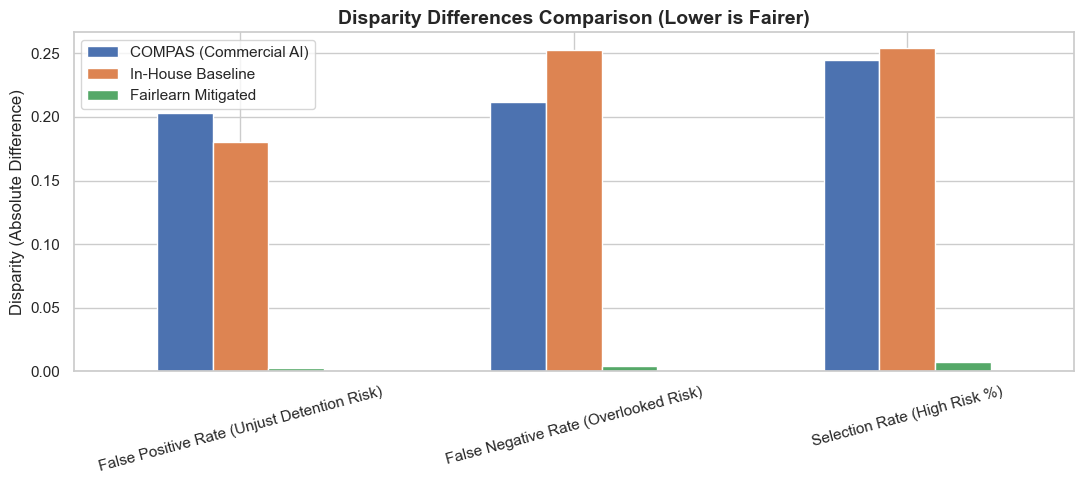

In [21]:
# Compile comparison dataframe
comparison_df = pd.DataFrame({
    "COMPAS (Commercial AI)": compas_audit.difference(),
    "In-House Baseline": baseline_audit.difference(),
    "Fairlearn Mitigated": mitigated_audit.difference()
}).drop("Sample Count")

display(comparison_df.round(3))

# Plot the comparison
comparison_df.loc[
    ["False Positive Rate (Unjust Detention Risk)", 
     "False Negative Rate (Overlooked Risk)", 
     "Selection Rate (High Risk %)"]
].plot(kind="bar", figsize=(11, 5), rot=15)

plt.title("Disparity Differences Comparison (Lower is Fairer)", fontsize=14, fontweight="bold")
plt.ylabel("Disparity (Absolute Difference)")
plt.tight_layout()
plt.show()


---
## Step 6: Critical Legal and Sociotechnical Takeaways

When deploying or auditing AI in the justice system, keep the following core tenets in mind:

1. **The Impossibility Theorem of Fairness**:
   * Mathematical proofs (Chouldechova 2017, Kleinberg et al. 2016) show that when base rates of the target outcome differ between groups, **it is mathematically impossible to simultaneously satisfy Predictive Parity (Equal PPV) and Equalized Odds (Equal FPR/FNR)**.
   * Legal stakeholders must explicitly decide which definition of fairness takes priority based on constitutional law and human rights principles.

2. **The Problem of Label Bias**:
   * In criminal datasets, "recidivism" is measured by *re-arrest*, not *actual commission of crime*. Re-arrest rates reflect police behavior and patrol density, not just defendant behavior.
   * Algorithmic debiasing cannot fix underlying systemic data collection bias.

3. **Legal Admissibility (Disparate Treatment vs. Disparate Impact)**:
   * Under U.S. Equal Protection and anti-discrimination doctrines, using race as an explicit feature at decision time to adjust thresholds may trigger strict scrutiny.
   * In-processing reductions like `ExponentiatedGradient` train an overall model weight vector that minimizes disparity while scoring defendants strictly using their case attributes.
